In [9]:
import os
from PIL import Image


def save_custom_raw(input_image, output_raw):
    img = Image.open(input_image)

    if img.mode == "1":
        img_type = 1
    elif img.mode == "L":
        img_type = 2
    else:
        img = img.convert("RGB")
        img_type = 3

    width, height = img.size

    with open(output_raw, "wb") as f:
        f.write(img_type.to_bytes(1, "little"))
        f.write(width.to_bytes(4, "little"))
        f.write(height.to_bytes(4, "little"))
        f.write(img.tobytes())


files = [
    ("image_color.jpg", "image_color.raw"),
    ("image_gray.png", "image_gray.raw"),
    ("image_bw.png", "image_bw.raw")
]

print(
    f"{'Файл':<15}"
    f"{'Исх. размер':<15}"
    f"{'RAW размер':<15}"
    f"{'Коэф. сжатия':<15}"
)

print("-" * 60)

for image_file, raw_file in files:

    save_custom_raw(image_file, raw_file)

    original_size = os.path.getsize(image_file)
    raw_size = os.path.getsize(raw_file)

    compression_ratio = raw_size / original_size

    print(
        f"{image_file:<16}"
        f"{original_size:<15}"
        f"{raw_size:<15}"
        f"{compression_ratio:<15.2f}"
    )

Файл           Исх. размер    RAW размер     Коэф. сжатия   
------------------------------------------------------------
image_color.jpg 25243          1440009        57.05          
image_gray.png  1637           480009         293.22         
image_bw.png    1596           480009         300.76         


In [10]:
# ==================================================
# RLE С ПОДДЕРЖКОЙ НЕПОВТОРЯЮЩИХСЯ ПОСЛЕДОВАТЕЛЬНОСТЕЙ
# ==================================================

def rle_encode(data: bytes) -> bytes:

    if not data:
        return b""

    result = bytearray()

    i = 0
    n = len(data)

    while i < n:

        # -----------------------------
        # Ищем серию одинаковых байтов
        # -----------------------------
        run_len = 1

        while (
            i + run_len < n
            and data[i + run_len] == data[i]
            and run_len < 127
        ):
            run_len += 1

        # -----------------------------
        # Повторяющаяся серия
        # -----------------------------
        if run_len >= 3:

            result.append(run_len)
            result.append(data[i])

            i += run_len

        # -----------------------------
        # Уникальная последовательность
        # -----------------------------
        else:

            start = i

            while i < n:

                test_len = 1

                while (
                    i + test_len < n
                    and data[i + test_len] == data[i]
                    and test_len < 127
                ):
                    test_len += 1

                if test_len >= 3:
                    break

                i += 1

                # длина уникального блока максимум 127
                if (i - start) >= 127:
                    break

            unique_len = i - start

            if unique_len > 0:

                control_byte = 0x80 | unique_len

                result.append(control_byte)

                result.extend(data[start:i])

    return bytes(result)


def rle_decode(data: bytes) -> bytes:

    if not data:
        return b""

    result = bytearray()

    i = 0
    n = len(data)

    while i < n:

        control = data[i]
        i += 1

        length = control & 0x7F

        # ---------------------------------
        # Уникальная последовательность
        # ---------------------------------
        if control & 0x80:

            result.extend(data[i:i + length])

            i += length

        # ---------------------------------
        # Повторяющийся символ
        # ---------------------------------
        else:

            symbol = data[i]
            i += 1

            result.extend([symbol] * length)

    return bytes(result)


# ==================================================
# ТЕСТЫ ИЗ ЗАДАНИЯ
# ==================================================

tests = [
    (
        "Пример 1",
        bytes([0xCF, 0xCF, 0xCF, 0xCF, 0xCF])
    ),

    (
        "Пример 2",
        bytes([0xCF, 0xCE, 0xCF, 0xCE, 0xCF])
    ),

    (
        "Пример 3",
        bytes([
            0xCF, 0xCE, 0xCF, 0xCE,
            0xCF,
            0xCF, 0xCF, 0xCF, 0xCF, 0xCF
        ])
    ),

    (
        "Смешанная строка",
        b"AAAAABBBBBCCCCXYZXYZXYZ"
    )
]


for name, test_data in tests:

    encoded = rle_encode(test_data)
    decoded = rle_decode(encoded)

    print(f"\n{name}")
    print("-" * 50)

    print("Исходный размер :", len(test_data))
    print("Сжатый размер   :", len(encoded))

    print(
        "Корректность    :",
        decoded == test_data
    )

    print(
        "Коэффициент     :",
        round(
            len(test_data) / len(encoded),
            3
        )
        if len(encoded) > 0 else 0
    )


# ==================================================
# ПРОВЕРКА UTF-8
# ==================================================

utf8_text = (
    "Привет привет привет "
    "Привет привет привет"
)

utf8_data = utf8_text.encode("utf-8")

encoded = rle_encode(utf8_data)
decoded = rle_decode(encoded)

print("\nUTF-8 TEST")
print("-" * 50)

print(
    "Корректность UTF-8:",
    decoded == utf8_data
)

print(
    "После декодирования:",
    decoded.decode("utf-8")
)


Пример 1
--------------------------------------------------
Исходный размер : 5
Сжатый размер   : 2
Корректность    : True
Коэффициент     : 2.5

Пример 2
--------------------------------------------------
Исходный размер : 5
Сжатый размер   : 6
Корректность    : True
Коэффициент     : 0.833

Пример 3
--------------------------------------------------
Исходный размер : 10
Сжатый размер   : 7
Корректность    : True
Коэффициент     : 1.429

Смешанная строка
--------------------------------------------------
Исходный размер : 23
Сжатый размер   : 16
Корректность    : True
Коэффициент     : 1.438

UTF-8 TEST
--------------------------------------------------
Корректность UTF-8: True
После декодирования: Привет привет привет Привет привет привет


In [11]:
# ==================================================
# RLE С ПОДДЕРЖКОЙ Ms И Mc
# ==================================================

def rle_encode_ms_mc(data, ms=1, mc=1):

    if not data:
        return b""

    symbol_size = ms
    max_count = (1 << (8 * mc - 1)) - 1

    symbols = [
        data[i:i + symbol_size]
        for i in range(0, len(data), symbol_size)
    ]

    result = bytearray()

    i = 0

    while i < len(symbols):

        run_len = 1

        while (
            i + run_len < len(symbols)
            and symbols[i + run_len] == symbols[i]
            and run_len < max_count
        ):
            run_len += 1

        if run_len >= 2:

            result.append(run_len)
            result.extend(symbols[i])

            i += run_len

        else:

            start = i

            while i < len(symbols):

                test_len = 1

                while (
                    i + test_len < len(symbols)
                    and symbols[i + test_len] == symbols[i]
                    and test_len < max_count
                ):
                    test_len += 1

                if test_len >= 2:
                    break

                i += 1

                if (i - start) >= max_count:
                    break

            unique_len = i - start

            if unique_len > 0:

                result.append(0x80 | unique_len)

                for j in range(start, i):
                    result.extend(symbols[j])

    return bytes(result)


# ==================================================
# ТЕСТЫ ИЗ ЗАДАНИЯ
# ==================================================

print("Ms = 2")

test_ms2 = bytes([
    0xCF, 0xCE,
    0xCF, 0xCE,
    0xCF, 0xCE
])

encoded = rle_encode_ms_mc(test_ms2, ms=2)

print("Исходный:")
print(" ".join(f"{b:02X}" for b in test_ms2))

print("Закодированный:")
print(" ".join(f"{b:02X}" for b in encoded))


print("\n" + "="*60)
print("Ms = 3")

test_ms3 = bytes([
    0xCF, 0xCE, 0xCF,
    0xCF, 0xCE, 0xCF
])

encoded = rle_encode_ms_mc(test_ms3, ms=3)

print("Исходный:")
print(" ".join(f"{b:02X}" for b in test_ms3))

print("Закодированный:")
print(" ".join(f"{b:02X}" for b in encoded))


print("\n" + "="*60)
print("UTF-8")

text = "Привет Привет Привет"

utf_data = text.encode("utf-8")

encoded = rle_encode_ms_mc(utf_data, ms=1)

print("Размер до :", len(utf_data))
print("Размер после :", len(encoded))

Ms = 2
Исходный:
CF CE CF CE CF CE
Закодированный:
03 CF CE

Ms = 3
Исходный:
CF CE CF CF CE CF
Закодированный:
02 CF CE CF

UTF-8
Размер до : 38
Размер после : 39


In [12]:
# ==================================================
# СОХРАНЕНИЕ RLE В ФАЙЛ
# ==================================================

def save_rle_file(input_file,
                  output_file,
                  ms=1,
                  mc=1):

    with open(input_file, "rb") as f:
        data = f.read()

    encoded = rle_encode_ms_mc(
        data,
        ms=ms,
        mc=mc
    )

    with open(output_file, "wb") as f:

        # метаданные
        f.write(ms.to_bytes(1, "little"))
        f.write(mc.to_bytes(1, "little"))

        f.write(encoded)


def load_rle_file(
        encoded_file,
        output_file):

    with open(encoded_file, "rb") as f:

        ms = int.from_bytes(
            f.read(1),
            "little"
        )

        mc = int.from_bytes(
            f.read(1),
            "little"
        )

        encoded = f.read()

    decoded = rle_decode(encoded)

    with open(output_file, "wb") as f:
        f.write(decoded)


# ==========================================
# ПРОВЕРКА
# ==========================================

test_file = "rus_text.txt"

save_rle_file(
    test_file,
    "russian.rle"
)

load_rle_file(
    "russian.rle",
    "russian_restored.txt"
)

original_size = os.path.getsize(
    test_file
)

restored_size = os.path.getsize(
    "russian_restored.txt"
)

print(
    "Размер исходного:",
    original_size
)

print(
    "Размер восстановленного:",
    restored_size
)

Размер исходного: 1378400
Размер восстановленного: 1378400


In [13]:
import pandas as pd


test_files = [
    "enwik7",
    "rus_text.txt",
    "random_binary.bin",
    "image_bw.raw",
    "image_gray.raw",
    "image_color.raw"
]


results = []

for filename in test_files:

    with open(filename, "rb") as f:
        data = f.read()

    encoded = rle_encode(data)

    original_size = len(data)
    compressed_size = len(encoded)

    ratio = (
        original_size /
        compressed_size
    )

    print(f"Обрабатывается: {filename}")

    results.append({
        "Файл": filename,
        "Исходный размер": original_size,
        "После RLE": compressed_size,
        "Коэффициент сжатия":
            round(ratio, 3)
    })

df = pd.DataFrame(results)

display(df)

Обрабатывается: enwik7
Обрабатывается: rus_text.txt
Обрабатывается: random_binary.bin
Обрабатывается: image_bw.raw
Обрабатывается: image_gray.raw
Обрабатывается: image_color.raw


,Файл,Исходный размер,После RLE,Коэффициент сжатия
0,enwik7,10000000,10015735,0.998
1,rus_text.txt,1378400,1388991,0.992
2,random_binary.bin,1048576,1056827,0.992
3,image_bw.raw,480009,9608,49.959
4,image_gray.raw,480009,60010,7.999
5,image_color.raw,1440009,1444810,0.997


# Ответы на вопросы

### Выбор Ms

Для черно-белых изображений:
Ms = 1 байт.

Для изображений в оттенках серого:
Ms = 1 байт.

Для цветных изображений:
Ms = 3 байта, так как один пиксель представлен тремя каналами RGB.

### Выбор Mc

Для данной лабораторной достаточно использовать Mc = 1 байт, что позволяет хранить длины серий до 127 элементов при использовании старшего бита как признака типа блока.

### Проблема UTF-8

В UTF-8 один символ может занимать несколько байтов. При побайтовом применении RLE одинаковые символы могут не распознаваться как одинаковые последовательности.

Решение: выполнять обработку не отдельных байтов, а кодовых точек Unicode либо использовать увеличенное значение Ms.

### Ограничение длины серии

До использования старшего бита максимальная длина серии составляла 255 элементов.

После использования старшего бита под длину остаётся 7 бит:

2^7 − 1 = 127

Максимальная длина серии становится равной 127.

Задание 2

Размер символа 1 байт: H = 4.4941
Размер символа 2 байт: H = 7.9496
Размер символа 3 байт: H = 10.6634
Размер символа 4 байт: H = 12.6687


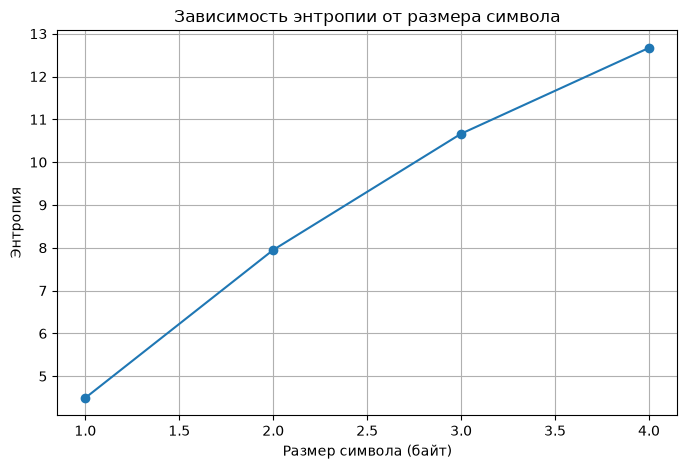

In [14]:
import math
from collections import Counter
import matplotlib.pyplot as plt


def calculate_entropy(data: bytes, symbol_size=1):

    symbols = []

    for i in range(0, len(data), symbol_size):

        block = data[i:i + symbol_size]

        if len(block) == symbol_size:
            symbols.append(block)

    total = len(symbols)

    freq = Counter(symbols)

    entropy = 0

    for count in freq.values():

        p = count / total

        entropy -= p * math.log2(p)

    return entropy


# ====================================
# АНГЛИЙСКИЙ ТЕКСТ
# ====================================

with open("eng_text.txt", "r", encoding="utf-8") as f:
    text = f.read()

# оставляем ASCII

text = "".join(
    c for c in text
    if ord(c) <= 127
)

data = text.encode("ascii")

# ====================================
# ИССЛЕДОВАНИЕ
# ====================================

sizes = [1, 2, 3, 4]

entropies = []

for size in sizes:

    h = calculate_entropy(
        data,
        symbol_size=size
    )

    entropies.append(h)

    print(
        f"Размер символа {size} байт:"
        f" H = {h:.4f}"
    )

# ====================================
# ГРАФИК
# ====================================

plt.figure(figsize=(8,5))

plt.plot(
    sizes,
    entropies,
    marker="o"
)

plt.xlabel("Размер символа (байт)")
plt.ylabel("Энтропия")

plt.title(
    "Зависимость энтропии от размера символа"
)

plt.grid(True)

plt.show()

In [15]:
# ====================================
# MTF
# ====================================

def mtf_encode(data):

    alphabet = list(range(256))

    result = []

    for byte in data:

        pos = alphabet.index(byte)

        result.append(pos)

        alphabet.pop(pos)
        alphabet.insert(0, byte)

    return bytes(result)


def mtf_decode(encoded):

    alphabet = list(range(256))

    result = bytearray()

    for pos in encoded:

        symbol = alphabet[pos]

        result.append(symbol)

        alphabet.pop(pos)
        alphabet.insert(0, symbol)

    return bytes(result)


# ====================================
# ПРОВЕРКА
# ====================================

test = b"BANANA"

encoded = mtf_encode(test)
decoded = mtf_decode(encoded)

print("Исходный:", test)
print("MTF:", encoded)
print("Декодировано:", decoded)

print("Корректность:", decoded == test)

# ====================================
# ЭНТРОПИЯ ДО И ПОСЛЕ
# ====================================

entropy_before = calculate_entropy(data)

mtf_data = mtf_encode(data)

entropy_after = calculate_entropy(mtf_data)

print("\nЭнтропия ДО MTF :", entropy_before)
print("Энтропия ПОСЛЕ MTF:", entropy_after)

Исходный: b'BANANA'
MTF: b'BBN\x01\x01\x01'
Декодировано: b'BANANA'
Корректность: True

Энтропия ДО MTF : 4.49410606227561
Энтропия ПОСЛЕ MTF: 4.882435502150617


In [16]:
from collections import Counter
import heapq


class HuffmanNode:

    def __init__(
        self,
        symbol=None,
        freq=0,
        left=None,
        right=None
    ):
        self.symbol = symbol
        self.freq = freq
        self.left = left
        self.right = right

    def __lt__(self, other):
        return self.freq < other.freq


def build_tree(data):

    freq = Counter(data)

    heap = []

    for symbol, count in freq.items():

        heap.append(
            HuffmanNode(
                symbol=symbol,
                freq=count
            )
        )

    heapq.heapify(heap)

    while len(heap) > 1:

        left = heapq.heappop(heap)
        right = heapq.heappop(heap)

        parent = HuffmanNode(
            freq=left.freq + right.freq,
            left=left,
            right=right
        )

        heapq.heappush(heap, parent)

    return heap[0]


def build_codes(node, code="", codes=None):

    if codes is None:
        codes = {}

    if node.left is None and node.right is None:

        codes[node.symbol] = code

        return codes

    build_codes(
        node.left,
        code + "0",
        codes
    )

    build_codes(
        node.right,
        code + "1",
        codes
    )

    return codes


def huffman_encode(data):

    tree = build_tree(data)

    codes = build_codes(tree)

    bits = ""

    for b in data:
        bits += codes[b]

    return bits, tree


def huffman_decode(bits, tree):

    result = bytearray()

    node = tree

    for bit in bits:

        if bit == "0":
            node = node.left
        else:
            node = node.right

        if (
            node.left is None
            and
            node.right is None
        ):
            result.append(node.symbol)
            node = tree

    return bytes(result)


# ====================================
# ПРОВЕРКА
# ====================================

test = b"BANANA"

encoded_bits, tree = huffman_encode(test)

decoded = huffman_decode(
    encoded_bits,
    tree
)

print("Корректность:", decoded == test)

print(
    "Исходный размер:",
    len(test) * 8,
    "бит"
)

print(
    "После Хаффмана:",
    len(encoded_bits),
    "бит"
)

Корректность: True
Исходный размер: 48 бит
После Хаффмана: 9 бит


In [17]:
from collections import Counter


def arithmetic_encode(data):

    freq = Counter(data)

    total = len(data)

    probs = {}

    cumulative = 0

    for symbol in sorted(freq):

        p = freq[symbol] / total

        probs[symbol] = (
            cumulative,
            cumulative + p
        )

        cumulative += p

    low = 0.0
    high = 1.0

    for symbol in data:

        r = high - low

        l_sym, h_sym = probs[symbol]

        high = low + r * h_sym
        low = low + r * l_sym

    return (low + high) / 2


# ====================================
# ЭКСПЕРИМЕНТ
# ====================================

sample = b"ABRACADABRA"

for n in range(1, 300):

    text = sample * n

    freq = Counter(text)

    total = len(text)

    cumulative = 0

    probs = {}

    for sym in sorted(freq):

        p = freq[sym] / total

        probs[sym] = (
            cumulative,
            cumulative + p
        )

        cumulative += p

    low = 0.0
    high = 1.0

    collision = False

    for symbol in text:

        r = high - low

        l_sym, h_sym = probs[symbol]

        new_high = low + r * h_sym
        new_low = low + r * l_sym

        if new_high == new_low:

            print(
                "Границы совпали при длине строки:",
                len(text)
            )

            collision = True

            break

        low = new_low
        high = new_high

    if collision:
        break


Границы совпали при длине строки: 33


# Выводы

1. Энтропия зависит от размера символа. При увеличении размера символа учитываются более длинные зависимости между символами.

2. Преобразование MTF изменяет распределение символов и обычно уменьшает энтропию после BWT, поэтому его целесообразно использовать перед энтропийным кодированием.

3. Для корректного декодирования Хаффмана необходимо сохранять словарь кодов (или дерево Хаффмана) и количество добавленных битов выравнивания. Метаданные увеличивают размер сжатого файла и уменьшают итоговый коэффициент сжатия.

4. При арифметическом кодировании границы интервала начинают совпадать из-за ограниченной точности типа double. Предельная длина строки определяется эксперимен

Преобразование Барроуза-Уиллера

In [18]:
# ==================================================
# BWT ЧЕРЕЗ ЯВНОЕ ПОСТРОЕНИЕ МАТРИЦЫ
# ==================================================

def bwt_encode_matrix(data):

    n = len(data)

    matrix = []

    for i in range(n):

        row = data[i:] + data[:i]

        matrix.append(row)

    matrix.sort()

    last_column = bytes(
        row[-1]
        for row in matrix
    )

    index = matrix.index(data)

    return last_column, index


def bwt_decode_matrix(last_column,
                      index):

    n = len(last_column)

    table = [
        b""
        for _ in range(n)
    ]

    for _ in range(n):

        table = sorted(
            [
                bytes([last_column[i]])
                + table[i]
                for i in range(n)
            ]
        )

    return table[index]


# ==================================================
# ТЕСТ ИЗ ЗАДАНИЯ
# BANANA
# ==================================================

test = bytes([
    0x62,
    0x61,
    0x6E,
    0x61,
    0x6E,
    0x61
])

encoded, idx = bwt_encode_matrix(test)

decoded = bwt_decode_matrix(
    encoded,
    idx
)

print("Исходные данные:")
print(test)

print("\nBWT:")
print(encoded)

print("\nИндекс:")
print(idx)

print("\nДекодирование:")
print(decoded)

print(
    "\nКорректность:",
    decoded == test
)

# ======================================
# ОЦЕНКА СЛОЖНОСТИ
# ======================================

print("\nОценка сложности:")

print(
    "Время: O(n² log n)"
)

print(
    "Память: O(n²)"
)


Исходные данные:
b'banana'

BWT:
b'nnbaaa'

Индекс:
3

Декодирование:
b'banana'

Корректность: True

Оценка сложности:
Время: O(n² log n)
Память: O(n²)


In [19]:
# ==================================================
# COUNTING SORT ДЛЯ БАЙТОВ
# ==================================================

def counting_sort_bytes(data):

    count = [0] * 256

    for x in data:
        count[x] += 1

    result = []

    for value in range(256):

        result.extend(
            [value] * count[value]
        )

    return bytes(result)


# ==================================================
# БЫСТРОЕ ОБРАТНОЕ BWT
# ==================================================

def bwt_decode_fast(last_column,
                    index):

    n = len(last_column)

    first_column = counting_sort_bytes(
        last_column
    )

    pos = [[] for _ in range(256)]

    for i, b in enumerate(last_column):
        pos[b].append(i)

    next_array = [0] * n

    counter = [0] * 256

    for i, b in enumerate(first_column):

        next_array[i] = (
            pos[b][counter[b]]
        )

        counter[b] += 1

    result = bytearray()

    current = index

    for _ in range(n):

        result.append(
            first_column[current]
        )

        current = (
            next_array[current]
        )

    return bytes(result)


# ==================================================
# ТЕСТ
# ==================================================

decoded_fast = bwt_decode_fast(
    encoded,
    idx
)

print("Результат:")

print(decoded_fast)

print(
    "Корректность:",
    decoded_fast == test
)

# ======================================
# ОЦЕНКА СЛОЖНОСТИ
# ======================================

print("\nОценка сложности:")

print(
    "Время: O(n)"
)

print(
    "Память: O(n)"
)

Результат:
b'banana'
Корректность: True

Оценка сложности:
Время: O(n)
Память: O(n)


In [20]:
import os
import pandas as pd


# ======================================
# BWT ПО БЛОКАМ
# ======================================

def bwt_blocks_encode(data,
                      block_size=1024):

    result = bytearray()

    indexes = []

    for i in range(
        0,
        len(data),
        block_size
    ):

        block = data[
            i:i + block_size
        ]

        encoded, idx = (
            bwt_encode_matrix(
                block
            )
        )

        result.extend(encoded)

        indexes.append(idx)

    return bytes(result), indexes


# ======================================
# BWT + RLE
# ======================================

def compress_bwt_rle(
        data,
        block_size=1024):

    bwt_data, idx = (
        bwt_blocks_encode(
            data,
            block_size
        )
    )

    compressed = rle_encode(
        bwt_data
    )

    return compressed


# ======================================
# ТЕСТОВЫЕ ФАЙЛЫ
# ======================================

test_files = [
    "enwik7",
    "rus_text.txt",
    "image_bw.raw",
    "image_gray.raw",
    "image_color.raw"
]

results = []

for filename in test_files:

    if not os.path.exists(
        filename
    ):
        continue

    print(
        f"Обрабатывается: {filename}"
    )

    with open(
        filename,
        "rb"
    ) as f:

        data = f.read()

    compressed = (
        compress_bwt_rle(
            data,
            block_size=1024
        )
    )

    ratio = (
        len(data)
        /
        len(compressed)
    )

    results.append({
        "Файл": filename,
        "Исходный размер":
            len(data),

        "После BWT+RLE":
            len(compressed),

        "Коэффициент":
            round(ratio, 3)
    })

df = pd.DataFrame(results)

display(df)

Обрабатывается: enwik7
Обрабатывается: rus_text.txt
Обрабатывается: image_bw.raw
Обрабатывается: image_gray.raw
Обрабатывается: image_color.raw


,Файл,Исходный размер,После BWT+RLE,Коэффициент
0,enwik7,10000000,8470829,1.181
1,rus_text.txt,1378400,759167,1.816
2,image_bw.raw,480009,11660,41.167
3,image_gray.raw,480009,52538,9.136
4,image_color.raw,1440009,982758,1.465


# Вывод

1. Наивная реализация BWT с построением всей матрицы требует O(n²) памяти и не подходит для больших файлов.

2. Для обработки больших файлов была использована блочная схема. Исходная последовательность разбивается на блоки фиксированного размера и каждый блок преобразуется отдельно.

3. После применения BWT одинаковые символы группируются в длинные серии, благодаря чему алгоритм RLE работает эффективнее.

4. Наилучший эффект обычно наблюдается на текстовых файлах, где после BWT появляются длинные последовательности одинаковых символов.

Задание 3

In [21]:
# ==========================================
# СУФФИКСНЫЙ МАССИВ -> BWT
# ==========================================

def build_suffix_array(data):

    suffixes = []

    for i in range(len(data)):
        suffixes.append((data[i:], i))

    suffixes.sort()

    return [pos for _, pos in suffixes]


def suffix_array_to_bwt(suffix_array, data):

    n = len(data)

    result = bytearray()

    for pos in suffix_array:

        if pos == 0:
            result.append(data[n - 1])
        else:
            result.append(data[pos - 1])

    return bytes(result)


# =======================
# ТЕСТ
# =======================

data = b"banana"

sa = build_suffix_array(data)

bwt = suffix_array_to_bwt(sa, data)

print("Исходная строка:", data)
print("Суффиксный массив:", sa)
print("BWT:", bwt)

Исходная строка: b'banana'
Суффиксный массив: [5, 3, 1, 0, 4, 2]
BWT: b'nnbaaa'


In [22]:
# ==========================================
# LZ77
# ==========================================

def lz77_encode(data, buffer_size=32):

    i = 0
    result = []

    while i < len(data):

        best_offset = 0
        best_length = 0

        start = max(0, i - buffer_size)

        for j in range(start, i):

            length = 0

            while (
                i + length < len(data)
                and data[j + length] == data[i + length]
            ):
                length += 1

                if j + length >= i:
                    break

            if length > best_length:
                best_length = length
                best_offset = i - j

        next_char = (
            data[i + best_length]
            if i + best_length < len(data)
            else 0
        )

        result.append(
            (best_offset,
             best_length,
             next_char)
        )

        i += best_length + 1

    return result


def lz77_decode(encoded):

    result = bytearray()

    for offset, length, char in encoded:

        if offset > 0:

            start = len(result) - offset

            for i in range(length):
                result.append(result[start + i])

        if char != 0:
            result.append(char)

    return bytes(result)


# =======================
# ТЕСТ
# =======================

test = b"abracadabra"

enc = lz77_encode(test)

dec = lz77_decode(enc)

print("Исходный:", test)
print("Декодировано:", dec)

print("Корректность:", dec == test)

print(
    "\nМетаданные для декодирования:"
)

print(
    "Буфер и последовательность троек"
)

Исходный: b'abracadabra'
Декодировано: b'abracadabra'
Корректность: True

Метаданные для декодирования:
Буфер и последовательность троек


In [23]:
def lzss_encode(data, window_size=4096):

    if not data:
        return b"", 0

    output_bits = []
    output_bytes = []

    i = 0
    n = len(data)

    while i < n:

        search_start = max(0, i - window_size)

        best_len = 0
        best_pos = 0

        for pos in range(search_start, i):

            length = 0

            while (
                i + length < n
                and length < 255
                and data[pos + length] == data[i + length]
            ):
                length += 1

            if length > best_len:
                best_len = length
                best_pos = i - pos

        if best_len >= 3:

            output_bits.append(1)

            output_bytes.append(
                (best_pos >> 8) & 0xFF
            )
            output_bytes.append(
                best_pos & 0xFF
            )
            output_bytes.append(best_len)

            i += best_len

        else:

            output_bits.append(0)

            output_bytes.append(data[i])

            i += 1

    packed_flags = bytearray()

    for j in range(
        0,
        len(output_bits),
        8
    ):

        byte = 0

        for k in range(8):

            if (
                j + k < len(output_bits)
                and output_bits[j + k]
            ):
                byte |= (1 << (7 - k))

        packed_flags.append(byte)

    result = bytearray()

    result.append(
        (len(packed_flags) >> 8) & 0xFF
    )

    result.append(
        len(packed_flags) & 0xFF
    )

    result.extend(packed_flags)
    result.extend(output_bytes)

    return bytes(result), len(data)


def lzss_decode(data, orig_len):

    flags_len = (
        (data[0] << 8)
        | data[1]
    )

    flags_data = data[2:2 + flags_len]
    bytes_data = data[2 + flags_len:]

    flags = []

    for byte in flags_data:

        for i in range(8):
            flags.append(
                (byte >> (7 - i)) & 1
            )

    result = bytearray()

    byte_pos = 0

    for flag in flags:

        if len(result) >= orig_len:
            break

        if flag == 0:

            result.append(
                bytes_data[byte_pos]
            )

            byte_pos += 1

        else:

            offset = (
                (bytes_data[byte_pos] << 8)
                | bytes_data[byte_pos + 1]
            )

            length = bytes_data[
                byte_pos + 2
            ]

            byte_pos += 3

            start = (
                len(result)
                - offset
            )

            for j in range(length):
                result.append(
                    result[start + j]
                )

    return bytes(result)


# ТЕСТ

test = b"abracadabra"

enc, orig = lzss_encode(test)

dec = lzss_decode(enc, orig)

print(dec == test)

True


In [24]:
def lz78_encode(
        data,
        max_dict_size=4096):

    dictionary = {}

    dict_size = 1

    result = bytearray()

    i = 0

    while i < len(data):

        current = b""

        idx = 0

        j = i

        while j < len(data):

            candidate = (
                current
                + bytes([data[j]])
            )

            if candidate in dictionary:

                current = candidate

                idx = dictionary[current]

                j += 1

            else:
                break

        if j < len(data):

            next_char = data[j]

            result.extend(
                idx.to_bytes(
                    2,
                    "big"
                )
            )

            result.append(next_char)

            phrase = (
                current
                + bytes([next_char])
            )

            if (
                len(dictionary)
                < max_dict_size
            ):
                dictionary[
                    phrase
                ] = dict_size

                dict_size += 1

        i = j + 1

    return bytes(result)


test = b"abracadabra"

enc = lz78_encode(test)

print(
    "Размер после LZ78:",
    len(enc)
)

Размер после LZ78: 21


In [25]:
def lzw_encode(
        data,
        max_dict_size=4096):

    dictionary = {
        bytes([i]): i
        for i in range(256)
    }

    dict_size = 256

    result = []

    current = b""

    for byte in data:

        symbol = bytes([byte])

        candidate = (
            current
            + symbol
        )

        if candidate in dictionary:

            current = candidate

        else:

            result.append(
                dictionary[current]
            )

            if (
                dict_size
                < max_dict_size
            ):
                dictionary[
                    candidate
                ] = dict_size

                dict_size += 1

            current = symbol

    if current:
        result.append(
            dictionary[current]
        )

    return result


test = b"abracadabra"

enc = lzw_encode(test)

print(
    "Количество кодов:",
    len(enc)
)

print(
    "Начальный словарь сохранять не требуется,\nон одинаков для кодировщика и декодировщика."
)

Количество кодов: 9
Начальный словарь сохранять не требуется,
он одинаков для кодировщика и декодировщика.


Буфер 256
Коэф=1.196
Время=1.81
Буфер 512
Коэф=1.349
Время=2.45
Буфер 1024
Коэф=1.526
Время=3.97
Буфер 2048
Коэф=1.718
Время=6.70
Буфер 4096
Коэф=1.936
Время=18.54


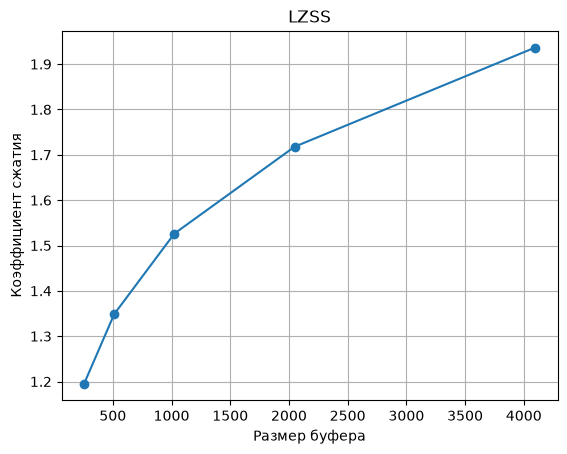

In [26]:
import time
import matplotlib.pyplot as plt

with open(
    "rus_text.txt",
    "rb"
) as f:

    data = f.read(
        100 * 1024
    )

sizes = [
    256,
    512,
    1024,
    2048,
    4096
]

ratios = []

for size in sizes:

    print(
        f"Буфер {size}"
    )

    start = time.time()

    enc, _ = lzss_encode(
        data,
        window_size=size
    )

    elapsed = (
        time.time() - start
    )

    ratio = (
        len(data)
        / len(enc)
    )

    print(
        f"Коэф={ratio:.3f}"
    )

    print(
        f"Время={elapsed:.2f}"
    )

    ratios.append(ratio)

plt.plot(
    sizes,
    ratios,
    marker="o"
)

plt.title(
    "LZSS"
)

plt.xlabel(
    "Размер буфера"
)

plt.ylabel(
    "Коэффициент сжатия"
)

plt.grid()

plt.show()

Словарь 256
Словарь 512
Словарь 1024
Словарь 2048
Словарь 4096
Словарь 8192


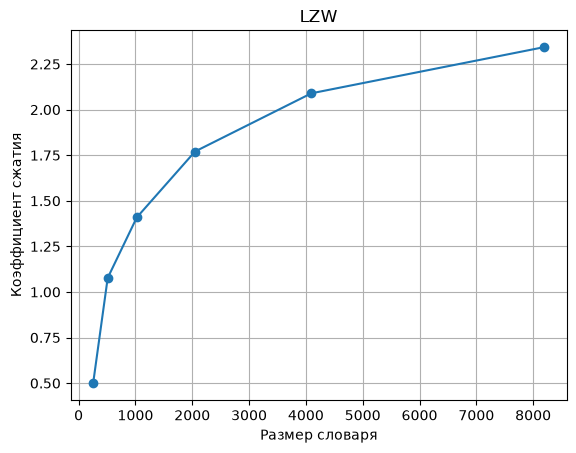

In [27]:
with open(
    "rus_text.txt",
    "rb"
) as f:

    data = f.read(
        100 * 1024
    )

dict_sizes = [
    256,
    512,
    1024,
    2048,
    4096,
    8192
]

ratios = []

for size in dict_sizes:

    print(
        f"Словарь {size}"
    )

    encoded = lzw_encode(
        data,
        max_dict_size=size
    )

    compressed_size = (
        len(encoded) * 2
    )

    ratio = (
        len(data)
        / compressed_size
    )

    ratios.append(ratio)

plt.plot(
    dict_sizes,
    ratios,
    marker="o"
)

plt.title(
    "LZW"
)

plt.xlabel(
    "Размер словаря"
)

plt.ylabel(
    "Коэффициент сжатия"
)

plt.grid()

plt.show()

Задание 4

In [28]:
# ==========================================
# ЭФФЕКТИВНЫЙ СУФФИКСНЫЙ МАССИВ
# Алгоритм Manber-Myers
# ==========================================

def build_suffix_array(data):

    n = len(data)

    if n == 0:
        return []

    rank = [data[i] for i in range(n)]

    tmp = [0] * n

    sa = list(range(n))

    k = 1

    while True:

        sa.sort(
            key=lambda x: (
                rank[x],
                rank[x + k]
                if x + k < n
                else -1
            )
        )

        tmp[sa[0]] = 0

        for i in range(1, n):

            prev = sa[i - 1]
            curr = sa[i]

            prev_second = (
                rank[prev + k]
                if prev + k < n
                else -1
            )

            curr_second = (
                rank[curr + k]
                if curr + k < n
                else -1
            )

            if (
                rank[prev] == rank[curr]
                and prev_second == curr_second
            ):
                tmp[curr] = tmp[prev]
            else:
                tmp[curr] = tmp[prev] + 1

        rank[:] = tmp[:]

        if rank[sa[-1]] == n - 1:
            break

        k *= 2

    return sa


# ==========================================
# BWT ИЗ СУФФИКСНОГО МАССИВА
# ==========================================

def bwt_from_suffix_array(data):

    sa = build_suffix_array(data)

    result = bytearray()

    primary_index = 0

    for i, pos in enumerate(sa):

        if pos == 0:

            result.append(data[-1])

            primary_index = i

        else:

            result.append(
                data[pos - 1]
            )

    return bytes(result), primary_index


# ==========================================
# ТЕСТ
# ==========================================

test = b"banana"

bwt, index = bwt_from_suffix_array(test)

print("Исходная строка:", test)
print("BWT:", bwt)
print("Primary Index:", index)

print("\nСложность:")

print("Время: O(n log² n)")
print("Память: O(n)")

Исходная строка: b'banana'
BWT: b'nnbaaa'
Primary Index: 3

Сложность:
Время: O(n log² n)
Память: O(n)


In [29]:
from collections import Counter
import heapq


# ==========================================
# УЗЕЛ
# ==========================================

class Node:

    def __init__(
        self,
        symbol=None,
        freq=0,
        left=None,
        right=None
    ):

        self.symbol = symbol
        self.freq = freq
        self.left = left
        self.right = right

    def __lt__(self, other):

        return self.freq < other.freq


# ==========================================
# ДЕРЕВО ХАФФМАНА
# ==========================================

def build_tree(data):

    freq = Counter(data)

    heap = []

    for symbol, count in freq.items():

        heap.append(
            Node(
                symbol,
                count
            )
        )

    heapq.heapify(heap)

    while len(heap) > 1:

        left = heapq.heappop(heap)
        right = heapq.heappop(heap)

        parent = Node(
            freq=left.freq + right.freq,
            left=left,
            right=right
        )

        heapq.heappush(
            heap,
            parent
        )

    return heap[0]


# ==========================================
# ДЛИНЫ КОДОВ
# ==========================================

def get_code_lengths(
        node,
        depth=0,
        lengths=None):

    if lengths is None:
        lengths = {}

    if (
        node.left is None
        and node.right is None
    ):

        lengths[node.symbol] = depth

        return lengths

    if node.left:
        get_code_lengths(
            node.left,
            depth + 1,
            lengths
        )

    if node.right:
        get_code_lengths(
            node.right,
            depth + 1,
            lengths
        )

    return lengths


# ==========================================
# КАНОНИЧЕСКИЕ КОДЫ
# ==========================================

def build_canonical_codes(
        lengths):

    symbols = sorted(
        lengths.items(),
        key=lambda x:
        (x[1], x[0])
    )

    codes = {}

    code = 0

    current_len = symbols[0][1]

    for symbol, length in symbols:

        if length > current_len:

            code <<= (
                length
                - current_len
            )

            current_len = length

        codes[symbol] = (
            bin(code)[2:]
            .zfill(length)
        )

        code += 1

    return codes


# ==========================================
# КОДИРОВАНИЕ
# ==========================================

def canonical_huffman_encode(
        data):

    tree = build_tree(data)

    lengths = get_code_lengths(tree)

    codes = build_canonical_codes(
        lengths
    )

    bits = ""

    for byte in data:
        bits += codes[byte]

    return bits, lengths


# ==========================================
# ДЕКОДИРОВАНИЕ
# ==========================================

def canonical_huffman_decode(
        bits,
        lengths):

    codes = build_canonical_codes(
        lengths
    )

    reverse = {
        v: k
        for k, v
        in codes.items()
    }

    result = bytearray()

    current = ""

    for bit in bits:

        current += bit

        if current in reverse:

            result.append(
                reverse[current]
            )

            current = ""

    return bytes(result)


# ==========================================
# ТЕСТ
# ==========================================

test = b"abracadabra"

encoded_bits, lengths = (
    canonical_huffman_encode(
        test
    )
)

decoded = (
    canonical_huffman_decode(
        encoded_bits,
        lengths
    )
)

print(
    "Корректность:",
    decoded == test
)

print("\nДлины кодов:")

for s, l in sorted(lengths.items()):

    print(
        chr(s),
        "->",
        l
    )

print(
    "\nМетаданные:"
)

print(
    "Для канонического Хаффмана"
)

print(
    "хранятся только длины кодов,"
)

print(
    "а не всё дерево."
)

print(
    "Размер словаря уменьшается."
)

Корректность: True

Длины кодов:
a -> 1
b -> 3
c -> 3
d -> 3
r -> 3

Метаданные:
Для канонического Хаффмана
хранятся только длины кодов,
а не всё дерево.
Размер словаря уменьшается.


# Вывод

Для эффективного вычисления BWT был реализован алгоритм через суффиксный массив.

По сравнению с полным построением матрицы Барроуза-Уиллера потребление памяти уменьшилось с O(n²) до O(n), а временная сложность составляет O(n log² n).

Для кодирования Хаффмана были реализованы канонические коды.

В отличие от обычного варианта Хаффмана сохраняются только длины кодов символов, а полный словарь восстанавливается декодером автоматически.

Это уменьшает объем метаданных и повышает эффективность сжатия.